# Analyse Exeperiments Results #

In [27]:
import numpy as np
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

## 26/02/2026 - Experiments ##

Experiments evaluating whether the addition of predicted RNA structures to the framework, incorporated through the gRNAde GNN encoder outputs (including comparisons between pre-trained and frozen weights), improves predictive performance under 5-fold cross-validation with early stopping on the full R-SIM dataset.

In [4]:
EXP_2602_PATH = '/home/gavrilev/Thesis/src/results/cv_all_2602.csv'

In [6]:
exp_2602_df = pd.read_csv(EXP_2602_PATH)
exp_2602_df

,exp,family,n_samples,rmse_mean,p_mean,s_mean,r2_mean
0,ex6,all_families_concat,1439,0.898370,0.769865,0.781522,0.585437
1,ex3,all_families_concat,1439,0.901239,0.765776,0.773600,0.582456
2,ex5,all_families_concat,1439,0.910558,0.761093,0.769447,0.573788
3,ex4,all_families_concat,1439,0.910228,0.761878,0.767007,0.574623
4,ex1,all_families_concat,1439,0.915362,0.759309,0.764469,0.569437
5,ex8,all_families_concat,1439,0.954442,0.732272,0.737344,0.531530
6,ex7,all_families_concat,1439,0.957778,0.731816,0.745027,0.528548
7,ex2,all_families_concat,1439,0.923669,0.751432,0.759119,0.561487
8,ex10,all_families_concat,1439,0.943581,0.743140,0.756201,0.542510


In [22]:
keep_exps = ["ex6", "ex7", "ex10"]
exp_name = {
    "ex6": "w FT gRNAde",
    "ex7": "w/o gRNAde",
    "ex10": "w gRNAde (frozen)"
}

metrics = ["rmse_mean", "p_mean", "s_mean", "r2_mean"]
metric_labels = {
    "rmse_mean": "RMSE",
    "p_mean": "Pearson r",
    "s_mean": "Spearman ρ",
    "r2_mean": "R²"
}

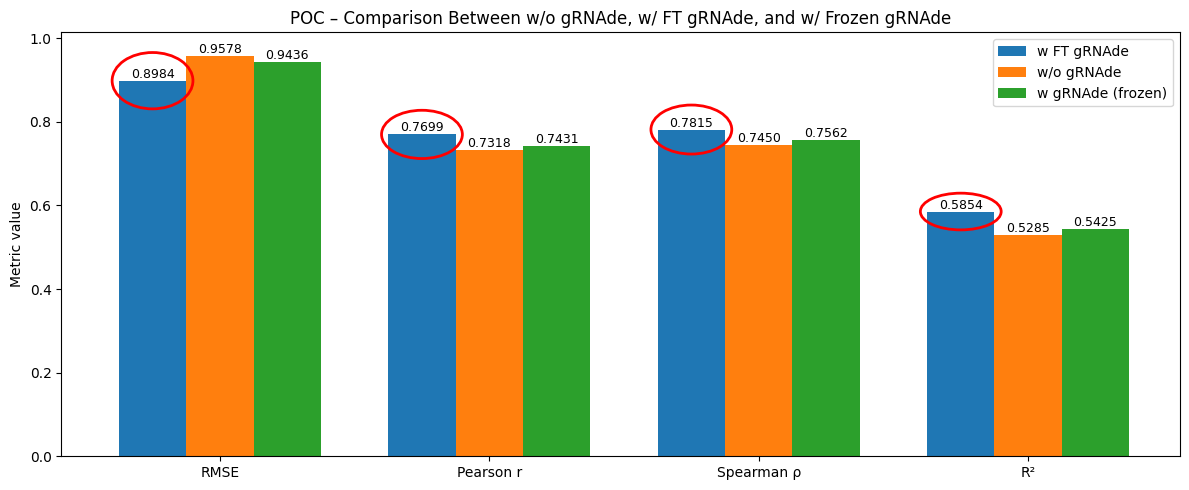

In [23]:
df3 = exp_2602_df[exp_2602_df["exp"].isin(keep_exps)].copy()
df3["exp"] = pd.Categorical(df3["exp"], categories=keep_exps, ordered=True)
df3 = df3.sort_values("exp")

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

bar_positions = []
bar_values = []

# plot bars
for i, exp in enumerate(keep_exps):
    row = df3[df3["exp"] == exp].iloc[0]
    y = [row[m] for m in metrics]
    positions = x + (i - 1) * width

    bars = ax.bar(positions, y, width, label=exp_name[exp])
    
    bar_positions.append(positions)
    bar_values.append(y)

    # value labels
    for j, val in enumerate(y):
        ax.text(positions[j], val, f"{val:.4f}", 
                ha="center", va="bottom", fontsize=9)

# convert to numpy for easier indexing
bar_positions = np.array(bar_positions)
bar_values = np.array(bar_values)

# ---- circle best bars ----
for j, metric in enumerate(metrics):
    values = bar_values[:, j]

    # define best rule
    if metric == "rmse_mean":
        best_idx = np.argmin(values)   # lower is better
    else:
        best_idx = np.argmax(values)   # higher is better

    best_x = bar_positions[best_idx, j]
    best_y = values[best_idx]

    # draw ellipse around best bar
    circle = Ellipse((best_x, best_y), width=0.3, height=best_y * 0.15,
                     edgecolor='red', facecolor='none', linewidth=2)
    ax.add_patch(circle)


ax.set_xticks(x)
ax.set_xticklabels([metric_labels[m] for m in metrics])
ax.set_ylabel("Metric value")
ax.set_title("POC – Comparison Between w/o gRNAde, w/ FT gRNAde, and w/ Frozen gRNAde")
ax.legend()
plt.tight_layout()
plt.show()

### Statistical Significance Test ###

To evaluate whether the addition of gRNAde is statistically significant, we extract the per-fold results from the 5-fold cross-validation log files manually.

In [24]:
rmse_exp6 = [0.89133006, 0.91608900, 0.91477060, 0.93576620, 0.83389515]
ppc_exp6 = [0.76407146, 0.76415807, 0.77316290, 0.74634160, 0.80159175]


rmse_exp7 = [0.91573500, 0.98097310, 1.04184170, 0.96920276, 0.88113594]
ppc_exp7 = [0.75264394, 0.72768265, 0.68671200, 0.72096086, 0.77108080]

rmse_exp10 = [0.92127630, 0.92776436, 1.01632710, 0.95846975, 0.89406765]
ppc_exp10 = [0.75697210, 0.75815450, 0.71103130,0.72839210,0.76114964]

In [26]:


#  WITH gRNAde
ppc_with = np.array([0.7641, 0.7642, 0.7732, 0.7463, 0.8016])
rmse_with = np.array([0.8913, 0.9161, 0.9148, 0.9358, 0.8339])

# WITHOUT gRNAde
ppc_without = np.array([0.7526, 0.7277, 0.6867, 0.7210, 0.7711])
rmse_without = np.array([0.9157, 0.9810, 1.0418, 0.9692, 0.8811])



# paired t-test
print("\n===== Paired t-test =====")

# Pearson (higher is better → test with >)
t_ppc, p_ppc_two = stats.ttest_rel(ppc_with, ppc_without)
p_ppc_one = p_ppc_two / 2 if t_ppc > 0 else 1 - (p_ppc_two / 2)

print(f"Pearson t-stat: {t_ppc:.4f}")
print(f"Pearson p-value (two-sided): {p_ppc_two:.6f}")
print(f"Pearson p-value (one-sided, with > without): {p_ppc_one:.6f}")

# RMSE (lower is better → test with <)
t_rmse, p_rmse_two = stats.ttest_rel(rmse_with, rmse_without)
p_rmse_one = p_rmse_two / 2 if t_rmse < 0 else 1 - (p_rmse_two / 2)

print(f"\nRMSE t-stat: {t_rmse:.4f}")
print(f"RMSE p-value (two-sided): {p_rmse_two:.6f}")
print(f"RMSE p-value (one-sided, with < without): {p_rmse_one:.6f}")


===== Paired t-test =====
Pearson t-stat: 2.9746
Pearson p-value (two-sided): 0.040958
Pearson p-value (one-sided, with > without): 0.020479

RMSE t-stat: -3.2565
RMSE p-value (two-sided): 0.031184
RMSE p-value (one-sided, with < without): 0.015592
